# 05 — Model Explainability

Two levels of explanation for the final model:

1. **Global** — which features carry the most predictive signal overall (model coefficients + SHAP summary).
2. **Individual** — why the model assigns a specific customer a high (or low) churn probability (per-customer SHAP waterfall).

**Interpretation rule:** these are *predictive* explanations. They show what the model relies on, not what causes churn. Nothing in this notebook supports causal claims.

In [1]:
import sys
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p for p in _candidates if (p / "src").exists())
sys.path.insert(0, str(PROJECT_ROOT))
import warnings
warnings.filterwarnings("ignore")

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import train_test_split

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "telco_features.csv")
meta = json.loads((PROJECT_ROOT / "models" / "model_metadata.json").read_text())
final_model = joblib.load(PROJECT_ROOT / "models" / "final_model.joblib")

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["customerID", "Churn", "churn_flag"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=meta["random_state"]
)

prep = final_model.named_steps["preprocessor"]
clf = final_model.named_steps["model"]
Z_train = prep.transform(X_train)
Z_test = prep.transform(X_test)
feat_names = [n.replace("num__", "").replace("cat__", "") for n in prep.get_feature_names_out()]
print("transformed feature matrix:", Z_train.shape)


transformed feature matrix: (5634, 57)


## 1. Global signal — model coefficients

For regularized logistic regression, the standardized coefficient is the model-native importance: the signed change in log-odds per standard deviation of the feature.

tenure                        -0.490
Contract_Month-to-month        0.478
Contract_Two year             -0.471
tenure_band_0-6 mo             0.393
avg_monthly_to_date            0.225
InternetService_DSL           -0.217
MonthlyCharges                 0.209
InternetService_Fiber optic    0.209
PaperlessBilling_No           -0.207
MultipleLines_No              -0.185
tenure_band_25-48 mo          -0.184
OnlineSecurity_Yes            -0.176
TechSupport_Yes               -0.171
tenure_band_13-24 mo          -0.170
PhoneService_Yes              -0.169


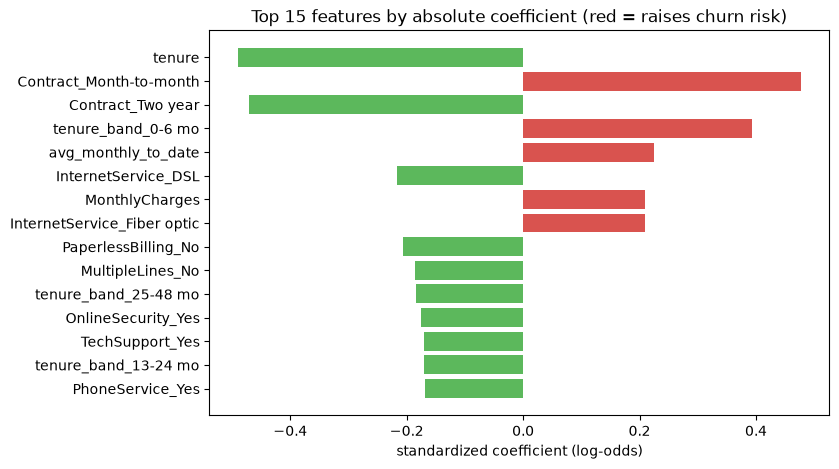

In [2]:
coefs = pd.Series(clf.coef_[0], index=feat_names).sort_values(key=np.abs, ascending=False)
top = coefs.head(15)
print(top.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#d9534f' if v > 0 else '#5cb85c' for v in top]
ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
ax.set(xlabel='standardized coefficient (log-odds)', title='Top 15 features by absolute coefficient (red = raises churn risk)')
fig.savefig(PROJECT_ROOT / 'reports' / 'figures' / 'lr_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

coefs.rename('coefficient').to_csv(PROJECT_ROOT / 'reports' / 'top_model_features.csv')

## 2. Global signal — SHAP

SHAP values decompose each prediction into per-feature contributions against a background expectation. A background sample of the training matrix keeps computation fast; the model is linear so LinearExplainer applies.

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


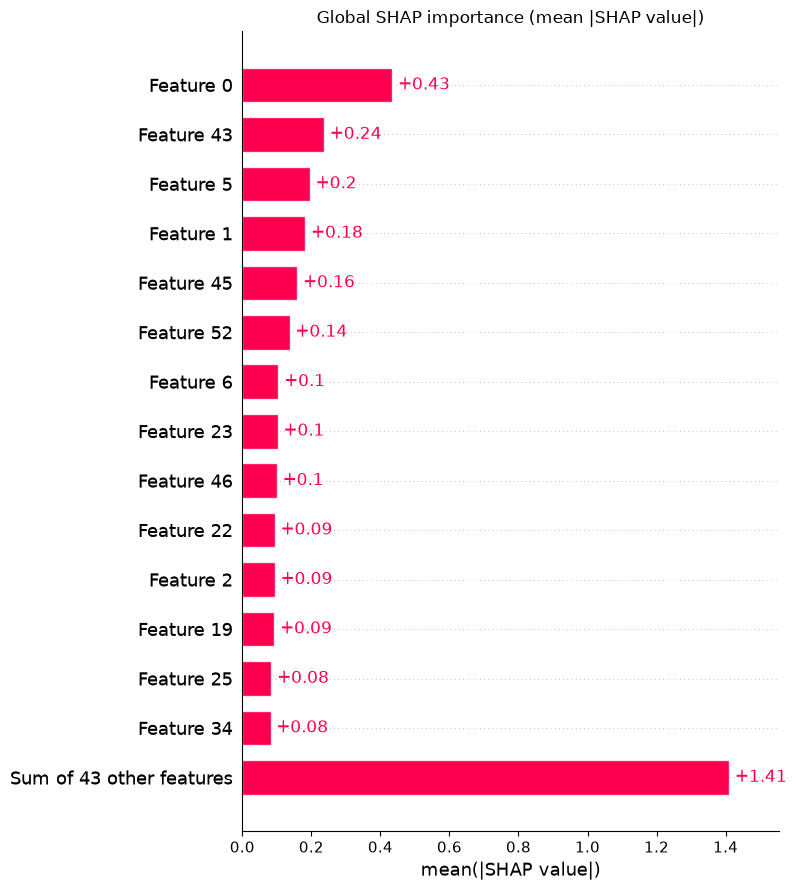

In [3]:
background = shap.sample(Z_train, 200, random_state=0)
explainer = shap.LinearExplainer(clf, background)
explainer_z = explainer(Z_test)

shap.plots.bar(explainer_z, max_display=15, show=False)
plt.title('Global SHAP importance (mean |SHAP value|)')
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'reports' / 'figures' / 'shap_global_bar.png', dpi=150, bbox_inches='tight')
plt.show()

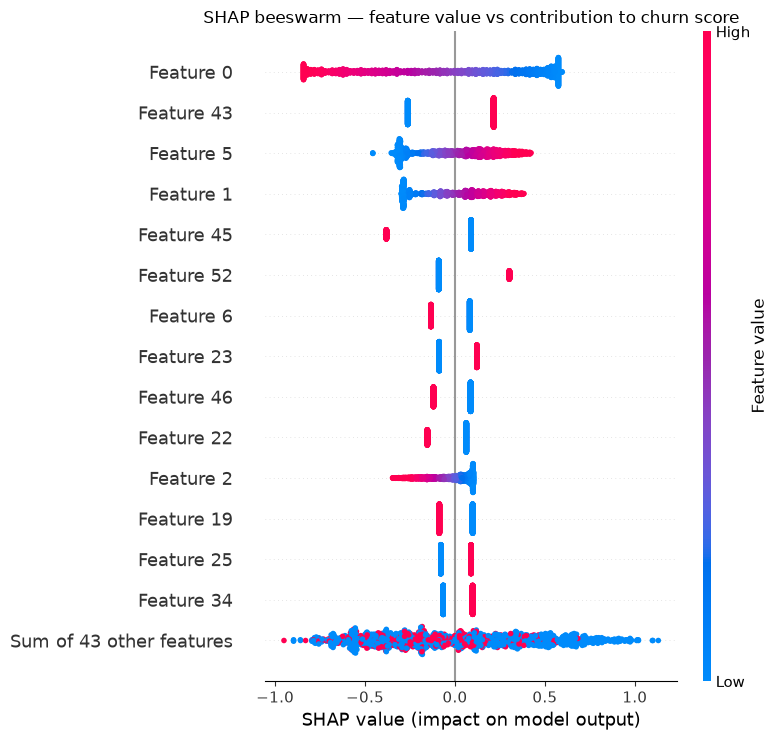

In [4]:
shap.plots.beeswarm(explainer_z, max_display=15, show=False)
plt.title('SHAP beeswarm — feature value vs contribution to churn score')
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'reports' / 'figures' / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Individual explanations — 'why does the model think this customer will churn?'

Two held-out customers are explained end-to-end: the customer with the highest predicted churn probability and one with a low probability, including their actual account profile for context.

In [5]:
probs = final_model.predict_proba(X_test)[:, 1]
idx_high = int(np.argmax(probs))
idx_low = int(np.argmin(probs))
print(f'highest predicted churn probability: {probs[idx_high]:.3f} (actual: {y_test.iloc[idx_high]})')
print(f'lowest  predicted churn probability: {probs[idx_low]:.3f} (actual: {y_test.iloc[idx_low]})')

profile_cols = ['Contract', 'tenure', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'MonthlyCharges', 'addon_count']
print('\nHigh-risk customer profile:')
print(X_test.iloc[idx_high][profile_cols].to_string())
print('\nLow-risk customer profile:')
print(X_test.iloc[idx_low][profile_cols].to_string())

highest predicted churn probability: 0.954 (actual: 1)
lowest  predicted churn probability: 0.024 (actual: 0)

High-risk customer profile:
Contract             Month-to-month
tenure                            1
InternetService         Fiber optic
PaymentMethod      Electronic check
OnlineSecurity                   No
TechSupport                      No
MonthlyCharges                 95.1
addon_count                       2

Low-risk customer profile:
Contract                            Two year
tenure                                    72
InternetService                           No
PaymentMethod      Bank transfer (automatic)
OnlineSecurity           No internet service
TechSupport              No internet service
MonthlyCharges                         19.55
addon_count                                0


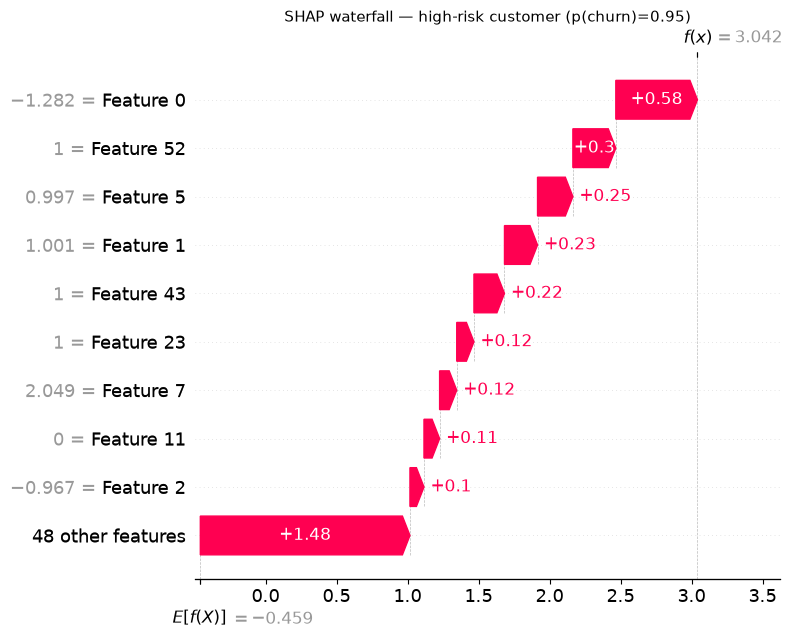

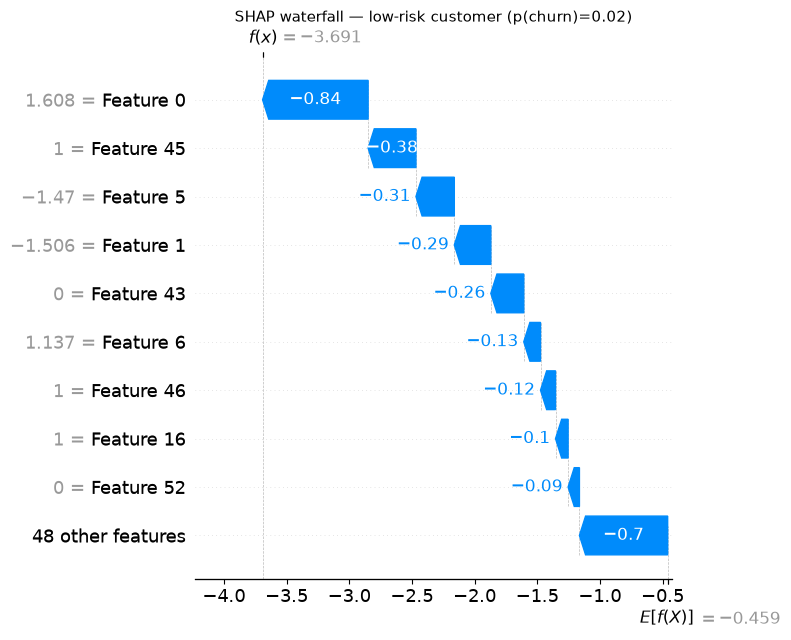

In [6]:
for label, idx in [('high-risk customer', idx_high), ('low-risk customer', idx_low)]:
    expl_i = explainer(Z_test[[idx]])
    plt.figure()
    shap.plots.waterfall(expl_i[0], max_display=10, show=False)
    plt.title(f'SHAP waterfall — {label} (p(churn)={probs[idx]:.2f})', fontsize=11)
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / 'reports' / 'figures' / f'shap_waterfall_{label.split("-")[0]}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 4. Reading an individual explanation

The waterfall starts from the population baseline (average model output) and adds each feature's contribution for this customer. Red bars push the prediction toward churn, blue bars push toward staying. For the high-risk customer the story reads like the EDA findings combined: contract type, tenure band, payment method and missing protective add-ons all push the same direction — that is exactly the kind of narrative a retention agent can act on.

**Calibration caveat:** because the model uses class weighting, predicted probabilities are systematically shifted upward relative to true base rates. The *ranking* of customers is unaffected, so risk tiers and prioritization are valid; the probabilities themselves should be read as risk scores, not literal chances. If calibrated probabilities become a business requirement, apply a CalibratedClassifierCV (isotonic/sigmoid) on top — noted in README limitations.

## Global findings summary

- Contract type dominates: month-to-month contracts are the strongest churn signal in both coefficients and SHAP.
- Tenure (and its banded version) is the strongest retention signal — long-tenure customers score far below baseline.
- Fiber-optic internet, electronic-check payment and missing OnlineSecurity/TechSupport all raise predicted risk.
- Add-on count and automatic payment reduce predicted risk.
- All statements are predictive associations observed by the model on this dataset — not causal effects.